# 패션 이커머스 AI 어시스턴트 — 01. 데이터 불러오기 & EDA

**프로젝트 전체 흐름**
1. **데이터 탐색 (EDA)** ← 지금 여기
2. 추천 (함께 산 상품 → 개인화 추천)
3. 의미 검색 (상품 임베딩)
4. 리뷰 요약 (LLM)
5. RAG 챗봇
6. (선택) Next.js 화면

**데이터**: Amazon Reviews 2023 (McAuley Lab) — `Amazon_Fashion` 카테고리
- 리뷰 파일 약 1GB, 상품 메타데이터 파일 별도
- 리뷰와 상품은 `parent_asin`(상품 ID)으로 연결됩니다

> 이 노트북의 목표: 데이터를 불러와서 구조를 이해하고, 다음 단계(추천)에서 쓸 **정제된 데이터를 parquet으로 저장**하는 것.

## 0. 환경 설정
구글 드라이브에 데이터를 저장해두면 런타임이 끊겨도 다시 다운로드하지 않아도 돼요.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/fashion-ai-assistant'
RAW_DIR = f'{PROJECT_DIR}/data/raw'
PROCESSED_DIR = f'{PROJECT_DIR}/data/processed'
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)
print('프로젝트 폴더:', PROJECT_DIR)

Mounted at /content/drive
프로젝트 폴더: /content/drive/MyDrive/fashion-ai-assistant


In [ ]:
!pip install -q huggingface_hub pyarrow

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid')

## 1. 데이터 다운로드
Hugging Face에서 리뷰 파일과 상품 메타데이터 파일을 받습니다. 이미 받은 파일이 있으면 건너뜁니다.

In [ ]:
from huggingface_hub import hf_hub_download

REPO_ID = 'McAuley-Lab/Amazon-Reviews-2023'
CATEGORY = 'Amazon_Fashion'

files = {
    'review': f'raw/review_categories/{CATEGORY}.jsonl',
    'meta':   f'raw/meta_categories/meta_{CATEGORY}.jsonl',
}

paths = {}
for key, filename in files.items():
    paths[key] = hf_hub_download(
        repo_id=REPO_ID,
        filename=filename,
        repo_type='dataset',
        local_dir=RAW_DIR,
    )
    size_mb = os.path.getsize(paths[key]) / 1024**2
    print(f'{key:6s} -> {paths[key]}  ({size_mb:,.0f} MB)')

raw/review_categories/Amazon_Fashion.jso(…): reconstructing file:   0%|          |  0.00B / 1.05GB            

raw/review_categories/Amazon_Fashion.jso(…): downloading bytes:           |  0.00B            

review -> /content/drive/MyDrive/fashion-ai-assistant/data/raw/raw/review_categories/Amazon_Fashion.jsonl  (1,003 MB)


raw/meta_categories/meta_Amazon_Fashion.(…): reconstructing file:   0%|          |  0.00B / 1.42GB            

raw/meta_categories/meta_Amazon_Fashion.(…): downloading bytes:           |  0.00B            

meta   -> /content/drive/MyDrive/fashion-ai-assistant/data/raw/raw/meta_categories/meta_Amazon_Fashion.jsonl  (1,356 MB)


## 2. 데이터 불러오기

### 2-1. 리뷰 데이터
| 컬럼 | 의미 |
|---|---|
| `rating` | 별점 (1~5) |
| `title`, `text` | 리뷰 제목, 본문 |
| `user_id` | 유저 ID |
| `parent_asin` | 상품 ID (색상·사이즈 옵션을 묶은 대표 상품) |
| `timestamp` | 작성 시각 (밀리초) |
| `helpful_vote` | '도움돼요' 수 |
| `verified_purchase` | 실제 구매 여부 |

In [ ]:
REVIEW_COLS = ['rating', 'title', 'text', 'user_id', 'parent_asin',
               'timestamp', 'helpful_vote', 'verified_purchase']

chunks = pd.read_json(paths['review'], lines=True, chunksize=500_000)
reviews = pd.concat([c[REVIEW_COLS] for c in chunks], ignore_index=True)

reviews['timestamp'] = pd.to_datetime(reviews['timestamp'], unit='ms')
print(reviews.shape)
reviews.head()

(2500939, 8)


,rating,title,text,user_id,parent_asin,timestamp,helpful_vote,verified_purchase
0,5,Pretty locket,I think this locket is really pretty. The inside back is a solid silver depr...,AGBFYI2DDIKXC5Y4FARTYDTQBMFQ,B00LOPVX74,2020-01-09 00:06:34.489,3,True
1,5,A,Great,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,B07B4JXK8D,2020-12-20 01:04:06.701,0,True
2,2,Two Stars,One of the stones fell out within the first 2 weeks of wearing it. Stones sm...,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,B007ZSEQ4Q,2015-05-23 01:33:48.000,3,True
3,1,Won’t buy again,Crappy socks. Money wasted. Bought to wear with my tieks. Don’t stay on feet...,AFVNEEPDEIH5SPUN5BWC6NKL3WNQ,B07F2BTFS9,2018-12-31 20:57:27.095,2,True
4,5,I LOVE these glasses,"I LOVE these glasses! They fit perfectly over my regular, rectangular glass...",AHSPLDNW5OOUK2PLH7GXLACFBZNQ,B00XESJTDE,2015-08-13 14:29:26.000,0,True


### 2-2. 상품 메타데이터
메타데이터는 이미지, 상세정보 같은 중첩 필드가 많아서 필요한 것만 골라서 읽어요.
- `features`, `description`은 리스트라서 하나의 문자열로 합칩니다 → 3단계 **의미 검색**에서 임베딩할 텍스트가 돼요.
- `images`에서는 대표 이미지 URL 하나만 뽑아둡니다 → 나중에 화면에 상품 사진을 띄울 때 사용.

In [ ]:
def first_image(images):
    if not images:
        return None
    img = images[0]
    return img.get('large') or img.get('hi_res') or img.get('thumb')

rows = []
with open(paths['meta'], 'r') as f:
    for line in f:
        m = json.loads(line)
        rows.append({
            'parent_asin':    m.get('parent_asin'),
            'title':          m.get('title'),
            'main_category':  m.get('main_category'),
            'store':          m.get('store'),
            'price':          m.get('price'),
            'average_rating': m.get('average_rating'),
            'rating_number':  m.get('rating_number'),
            'features':       ' '.join(m.get('features') or []),
            'description':    ' '.join(m.get('description') or []),
            'image_url':      first_image(m.get('images')),
        })

meta = pd.DataFrame(rows)
# 가격은 '$12.99', None, '—' 등 섞여 있어서 숫자로 변환 (안 되면 NaN)
meta['price'] = pd.to_numeric(meta['price'], errors='coerce')
print(meta.shape)
meta.head()

(826108, 10)


,parent_asin,title,main_category,store,price,average_rating,rating_number,features,description,image_url
0,B08BHN9PK5,YUEDGE 5 Pairs Men's Moisture Control Cushioned Dry Fit Casual Athletic Crew...,AMAZON FASHION,GiveGift,NaN,4.6,16,,,https://m.media-amazon.com/images/I/41+cCfaVOFS._AC_.jpg
1,B08R39MRDW,"DouBCQ Women's Palazzo Lounge Wide Leg Casual Flowy Pants(Flower Mix Blue, XL)",AMAZON FASHION,DouBCQ,NaN,4.1,7,Drawstring closure Machine Wash,,https://m.media-amazon.com/images/I/515cR-ta1EL._AC_.jpg
2,B077KJHCJ4,Pastel by Vivienne Honey Vanilla Girls' Trapeze Dress with Easy Removable La...,AMAZON FASHION,Pastel by Vivienne,NaN,4.3,11,Zipper closure Hand Wash Only,,https://m.media-amazon.com/images/I/31GwmwNCdAL._AC_.jpg
3,B0811M2JG9,Mento Streamtail,AMAZON FASHION,Guy Harvey,29.81,2.0,1,Thermoplastic Rubber sole High Density Premium Thickness Comfort Foam Footbe...,Slip on the Women's Mento and you're ready to hit the beach. This thong sand...,https://m.media-amazon.com/images/I/31P-uHUUIXL._AC_.jpg
4,B07SB2892S,RONNOX Women's 3-Pairs Bright Colored Calf Compression Tube Sleeves,AMAZON FASHION,RONNOX,17.99,4.3,3032,"Pull On closure Size Guide: ""S"" fits calf 10-12 inches. ""M"" fits calf 12-14 ...",Ronnox Calf Sleeves - Allowing Your Body to Perform at Its Best!Some of the ...,https://m.media-amazon.com/images/I/51CqMDJOODL._AC_.jpg


## 3. 기본 점검: 결측치와 중복

In [ ]:
print('=== 리뷰 결측치 비율 ===')
print(reviews.isna().mean().round(4))
print('\n=== 메타 결측치 비율 ===')
print(meta.isna().mean().round(4))

print('\n완전히 같은 리뷰 중복:', reviews.duplicated(['user_id', 'parent_asin', 'timestamp', 'text']).sum())
print('메타 상품 ID 중복:', meta['parent_asin'].duplicated().sum())

=== 리뷰 결측치 비율 ===
rating               0.0
title                0.0
text                 0.0
user_id              0.0
parent_asin          0.0
timestamp            0.0
helpful_vote         0.0
verified_purchase    0.0
dtype: float64

=== 메타 결측치 비율 ===
parent_asin       0.0000
title             0.0000
main_category     0.0000
store             0.0325
price             0.9392
average_rating    0.0000
rating_number     0.0000
features          0.0000
description       0.0000
image_url         0.0000
dtype: float64

완전히 같은 리뷰 중복: 25245
메타 상품 ID 중복: 0


## 4. EDA
### 4-1. 전체 규모

In [ ]:
n_reviews = len(reviews)
n_users = reviews['user_id'].nunique()
n_items = reviews['parent_asin'].nunique()
sparsity = 1 - n_reviews / (n_users * n_items)

print(f'리뷰 수     : {n_reviews:,}')
print(f'유저 수     : {n_users:,}')
print(f'상품 수     : {n_items:,}')
print(f'메타 상품 수: {len(meta):,}')
print(f'희소도      : {sparsity:.6%}  (유저-상품 표에서 비어 있는 칸의 비율)')

리뷰 수     : 2,500,939
유저 수     : 2,035,490
상품 수     : 825,869
메타 상품 수: 826,108
희소도      : 99.999851%  (유저-상품 표에서 비어 있는 칸의 비율)


### 4-2. 별점 분포

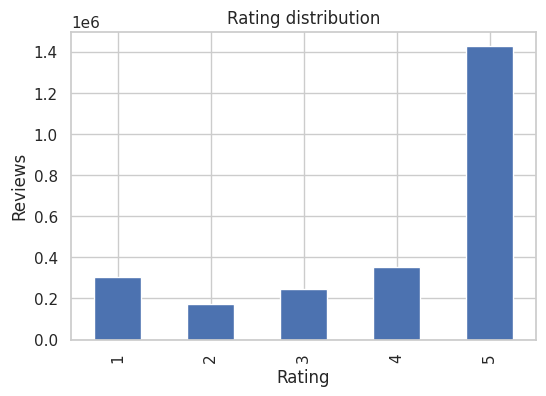

rating
1    0.121
2    0.069
3    0.098
4    0.141
5    0.570
Name: proportion, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
reviews['rating'].value_counts().sort_index().plot.bar(ax=ax, color='#4C72B0')
ax.set_xlabel('Rating'); ax.set_ylabel('Reviews'); ax.set_title('Rating distribution')
plt.show()

print(reviews['rating'].value_counts(normalize=True).sort_index().round(3))

### 4-3. 유저당 / 상품당 리뷰 수 (롱테일)
추천 시스템에서 가장 중요한 분석이에요. 리뷰를 1개만 쓴 유저가 대부분이면, 그 유저의 취향을 학습하기 어렵습니다(**콜드 스타트 문제**).

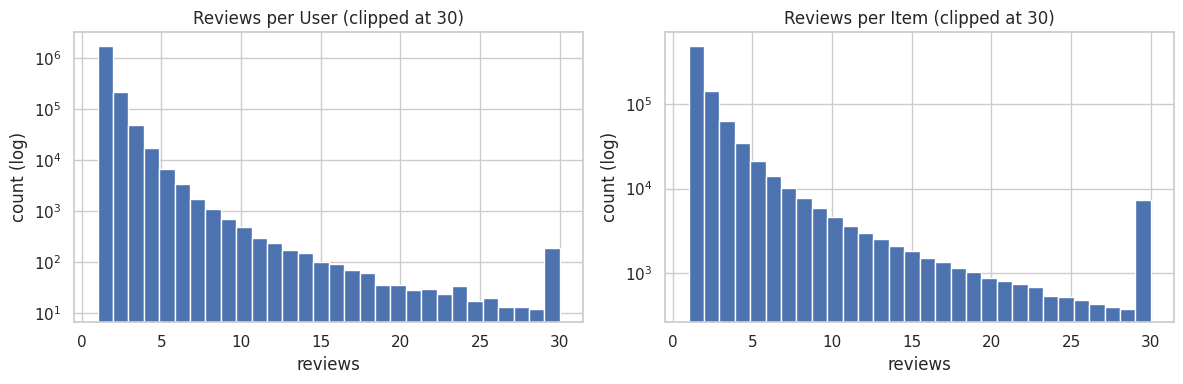

[유저] 1개만: 85.3% | 5개 이상: 0.8% | 최대: 311
[상품] 1개만: 59.3% | 5개 이상: 11.5% | 최대: 7,554


In [ ]:
user_cnt = reviews.groupby('user_id').size()
item_cnt = reviews.groupby('parent_asin').size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, cnt, name in [(axes[0], user_cnt, 'User'), (axes[1], item_cnt, 'Item')]:
    ax.hist(cnt.clip(upper=30), bins=30, color='#4C72B0')
    ax.set_yscale('log')
    ax.set_title(f'Reviews per {name} (clipped at 30)')
    ax.set_xlabel('reviews'); ax.set_ylabel('count (log)')
plt.tight_layout(); plt.show()

for name, cnt in [('유저', user_cnt), ('상품', item_cnt)]:
    print(f'[{name}] 1개만: {(cnt == 1).mean():.1%} | 5개 이상: {(cnt >= 5).mean():.1%} | 최대: {cnt.max():,}')

### 4-4. 시간에 따른 리뷰 수

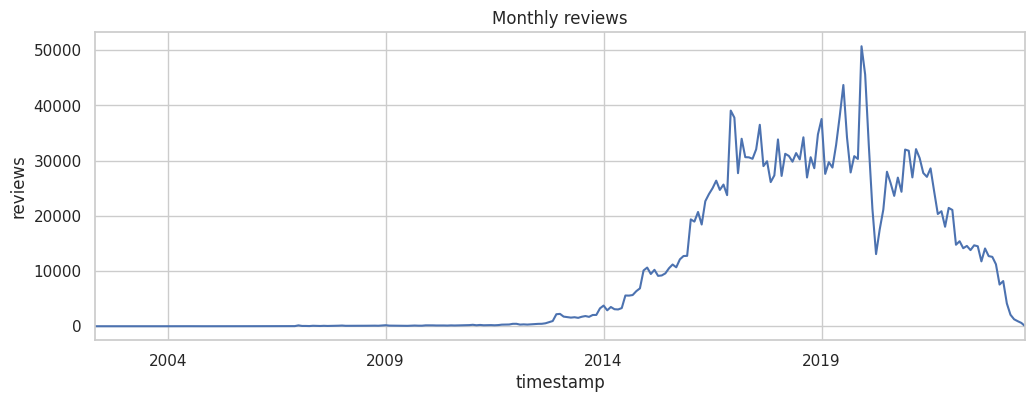

기간: 2002-05-07 ~ 2023-09-11


In [ ]:
monthly = reviews.set_index('timestamp').resample('ME').size()

fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot(ax=ax)
ax.set_title('Monthly reviews'); ax.set_ylabel('reviews')
plt.show()
print('기간:', reviews['timestamp'].min().date(), '~', reviews['timestamp'].max().date())

### 4-5. 리뷰 텍스트 길이
4단계 리뷰 요약에서 LLM에 넣을 텍스트 양을 가늠하는 데 필요해요.

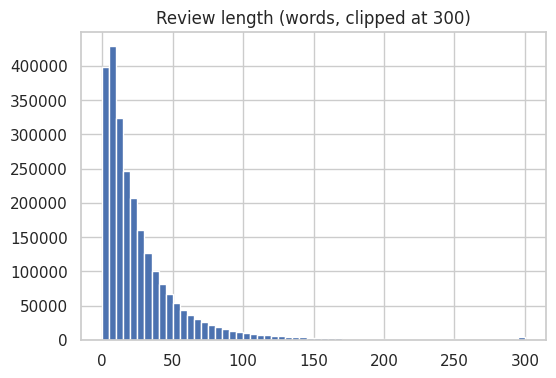

count    2500939.0
mean          27.0
std           35.5
min            0.0
25%            7.0
50%           16.0
75%           34.0
max         2221.0
Name: text_len, dtype: float64
rating
1    26.8
2    32.4
3    33.3
4    34.1
5    23.6
Name: text_len, dtype: float64


In [ ]:
reviews['text_len'] = reviews['text'].fillna('').str.split().str.len()

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(reviews['text_len'].clip(upper=300), bins=60, color='#4C72B0')
ax.set_title('Review length (words, clipped at 300)')
plt.show()
print(reviews['text_len'].describe().round(1))

# 별점별 평균 길이: 불만족 리뷰가 더 길까?
print(reviews.groupby('rating')['text_len'].mean().round(1))

### 4-6. 사이즈 관련 리뷰 비율
패션 커머스에서 사이즈는 반품의 주요 원인이라, 나중에 리뷰 요약과 챗봇에서 핵심 정보가 돼요.

In [ ]:
size_pattern = r'\b(?:size|fit|fits|small|large|tight|loose|runs)\b'
reviews['mentions_size'] = reviews['text'].fillna('').str.lower().str.contains(size_pattern, regex=True)
print(f"사이즈 언급 리뷰 비율: {reviews['mentions_size'].mean():.1%}")
print(reviews.groupby('rating')['mentions_size'].mean().round(3))

사이즈 언급 리뷰 비율: 33.1%
rating
1    0.317
2    0.405
3    0.431
4    0.408
5    0.289
Name: mentions_size, dtype: float64


### 4-7. 상품 메타데이터: 브랜드, 가격, 텍스트 품질

In [ ]:
print('상위 브랜드(store) 15개')
print(meta['store'].value_counts().head(15))

print('\n가격 정보가 있는 상품 비율:', f"{meta['price'].notna().mean():.1%}")
print(meta['price'].describe().round(2))

# 의미 검색에 쓸 텍스트가 충분한지 확인
meta['search_text'] = (meta['title'].fillna('') + ' ' + meta['features'] + ' ' + meta['description']).str.strip()
meta['search_text_len'] = meta['search_text'].str.split().str.len()
print('\n검색용 텍스트 길이(단어)')
print(meta['search_text_len'].describe().round(1))

상위 브랜드(store) 15개
store
Nike           5154
Romwe          4150
GRACE KARIN    3833
Verdusa        3723
Floerns        3441
SheIn          3066
Disney         2849
Ekouaer        2764
SweatyRocks    2661
Milumia        2186
Zeagoo         2165
Generic        2093
Allegra K      2014
DOUBLJU        1855
MakeMeChic     1773
Name: count, dtype: int64

가격 정보가 있는 상품 비율: 6.1%
count    50249.00
mean        40.80
std        154.09
min          0.01
25%         11.79
50%         19.89
75%         34.99
max      13000.00
Name: price, dtype: float64

검색용 텍스트 길이(단어)
count    826108.0
mean         29.8
std          55.9
min           0.0
25%          13.0
50%          17.0
75%          21.0
max        1248.0
Name: search_text_len, dtype: float64


In [ ]:
print(f"설명이 비어 있는 상품: {(meta['description'].str.strip() == '').mean():.1%}")
print(f"특징이 비어 있는 상품: {(meta['features'].str.strip() == '').mean():.1%}")

설명이 비어 있는 상품: 92.8%
특징이 비어 있는 상품: 43.9%


## 5. 다음 단계를 위한 데이터 정제

**k-core 필터링**: 리뷰가 너무 적은 유저와 상품을 반복해서 제거하는 방법이에요.
유저를 지우면 상품의 리뷰 수가 줄고, 상품을 지우면 유저의 리뷰 수가 줄어서 **변화가 없을 때까지 반복**해야 합니다.

Amazon Fashion은 희소한 데이터라 k=5는 너무 많이 날아갈 수 있어요. 아래 결과를 보고 `K` 값을 조정해보세요.

In [ ]:
def k_core(df, k, user_col='user_id', item_col='parent_asin'):
    df = df.copy()
    while True:
        before = len(df)
        u = df[user_col].map(df[user_col].value_counts())
        i = df[item_col].map(df[item_col].value_counts())
        df = df[(u >= k) & (i >= k)]
        if len(df) == before:
            return df

# 같은 유저가 같은 상품에 여러 번 리뷰를 남긴 경우 가장 최근 것만 사용
dedup = (reviews.sort_values('timestamp')
                .drop_duplicates(['user_id', 'parent_asin'], keep='last'))

for k in [2, 3, 5]:
    sub = k_core(dedup, k)
    print(f'k={k}: 리뷰 {len(sub):>9,} | 유저 {sub.user_id.nunique():>8,} | 상품 {sub.parent_asin.nunique():>8,}')

k=2: 리뷰   289,897 | 유저  118,869 | 상품   70,641
k=3: 리뷰    12,490 | 유저    2,223 | 상품    2,245
k=5: 리뷰         0 | 유저        0 | 상품        0


In [ ]:
K = 3  # 위 결과를 보고 조정
interactions = k_core(dedup, K)

# 상호작용에 등장하는 상품만 메타데이터에 남김
meta_sub = meta[meta['parent_asin'].isin(interactions['parent_asin'].unique())].drop_duplicates('parent_asin')

print('interactions:', interactions.shape)
print('meta_sub    :', meta_sub.shape)
print('메타 없는 상품:', interactions['parent_asin'].nunique() - len(meta_sub))

interactions: (12490, 10)
meta_sub    : (2245, 12)
메타 없는 상품: 0


In [ ]:
K = 2  # 위 결과를 보고 조정
interactions = k_core(dedup, K)

# 상호작용에 등장하는 상품만 메타데이터에 남김
meta_sub = meta[meta['parent_asin'].isin(interactions['parent_asin'].unique())].drop_duplicates('parent_asin')

print('interactions:', interactions.shape)
print('meta_sub    :', meta_sub.shape)
print('메타 없는 상품:', interactions['parent_asin'].nunique() - len(meta_sub))

interactions: (289897, 10)
meta_sub    : (70641, 12)
메타 없는 상품: 0


## 6. 저장
다음 노트북(02. 추천)에서는 이 파일들만 불러오면 돼요.

In [ ]:
interactions.to_parquet(f'{PROCESSED_DIR}/interactions_k{K}.parquet', index=False)
meta_sub.to_parquet(f'{PROCESSED_DIR}/items_k{K}.parquet', index=False)

# 전체 리뷰는 4단계(리뷰 요약)에서 다시 사용 — 필요한 컬럼만 저장
reviews[['user_id', 'parent_asin', 'rating', 'title', 'text', 'timestamp',
         'helpful_vote', 'verified_purchase']].to_parquet(f'{PROCESSED_DIR}/reviews_all.parquet', index=False)

for f in sorted(os.listdir(PROCESSED_DIR)):
    print(f, f'{os.path.getsize(os.path.join(PROCESSED_DIR, f)) / 1024**2:,.1f} MB')

interactions_k2.parquet 43.4 MB
interactions_k3.parquet 2.8 MB
items_k2.parquet 21.0 MB
items_k3.parquet 0.8 MB
reviews_all.parquet 343.8 MB


## 7. 정리해볼 질문 (블로그 / 포트폴리오용)
EDA 결과를 보고 아래 질문에 직접 답을 적어보세요. 면접에서 "데이터를 보고 어떤 판단을 했나요?"에 대한 답이 됩니다.

1. 리뷰를 1개만 쓴 유저 비율은? 개인화 추천만으로 충분할까?

리뷰를 1개만 쓴 유저가 전체의 [85.3]%였다. 이 유저들은 정보가 한 건뿐이라 취향을 학습하기 어렵다(콜드 스타트). 개인화 추천만 쓰면 대부분의 유저에게 제대로 된 추천을 줄 수 없다.

그래서 유저 상태에 따라 전략을 나누기로 했다.

기록이 거의 없는 유저: 인기 상품, 높은 평점 상품 추천
상품을 보고 있는 유저: 그 상품과 함께 구매된 상품 추천 (아이템 기반)
기록이 충분한 유저: 개인화 추천

실제 이커머스도 비로그인이나 신규 유저에게는 랭킹과 인기 상품을 보여주고, 활동이 쌓이면 개인화로 넘어가는 구조를 쓴다.

2. 별점이 5점에 몰려 있다면, 별점을 그대로 선호도로 써도 될까?

5점이 [57]%로 별점이 한쪽에 크게 치우쳐 있었다. 이런 데이터에서 별점을 그대로 선호도로 쓰면 대부분 값이 5라서 모델이 상품 간 차이를 구분하기 어렵다. 또 리뷰는 아주 만족했거나 아주 불만족한 사람이 주로 남기기 때문에 별점 자체에 편향이 있다.

그래서 별점 대신 리뷰를 남겼다는 사실 자체를 구매와 관심의 신호(implicit feedback) 로 보고, 상호작용이 있으면 1, 없으면 0으로 두는 방식을 택했다. 실제 커머스에서도 별점보다 클릭, 장바구니, 구매 같은 행동 데이터가 훨씬 많아서 이 방식이 일반적이다. 다만 1~2점 리뷰는 불만족 신호이므로, 낮은 별점을 제외하거나 가중치를 낮추는 실험을 추가로 해볼 수 있다.

3. 사이즈를 언급한 리뷰는 별점이 낮을수록 많은가?

사이즈 관련 단어가 들어간 리뷰는 전체의 33.1%였다. 별점별로 보면 1점 31.7%, 2점 40.5%, 3점 43.1%, 4점 40.8%, 5점 28.9%로, 별점이 낮을수록 많아지는 게 아니라 2~4점의 중간 평가에서 가장 높았다.

사이즈 문제는 상품을 완전히 실패로 만들기보다 "괜찮지만 아쉬운" 평가로 이어지는 경우가 많다고 해석했다. 구매를 고민하는 사람에게 가장 중요한 정보가 이런 중간 평가 리뷰에 몰려 있으므로, 리뷰 요약 단계에서 장단점과 별도로 "작게 나온다 / 정사이즈 / 크게 나온다" 같은 사이즈 정보를 따로 추출하기로 했다.

참고로 지금 방식은 단어 매칭이라 “fit”이 다른 뜻으로 쓰인 경우도 잡히는 한계가 있다. 이 부분은 4단계에서 LLM으로 보완할 예정이다.

4. 검색용 텍스트가 짧은 상품이 많다면, 의미 검색 품질을 어떻게 보완할까?

상품명, 특징, 설명을 합친 검색용 텍스트의 중앙값이 [ 17]단어였고, 설명이 비어 있는 상품은 92.8%로, 대부분의 상품이 사실상 상품명만으로 검색되는 상태였다. 상품명만으로는 "여름에 입기 좋은", "출근룩" 같은 표현과 매칭하기 어렵다.

보완 방법은 세 가지를 생각했다.

리뷰 텍스트 섞기: 리뷰에는 "통기성이 좋아요", "결혼식 하객룩으로 입었어요"처럼 판매자 설명에 없는 실제 사용 맥락이 들어 있다. 상품별 대표 리뷰 몇 개를 검색용 텍스트에 더한다.
LLM으로 속성 생성: 상품명과 설명을 바탕으로 소재, 계절, 스타일 같은 태그를 LLM이 만들어 붙인다.
키워드 검색과 결합(하이브리드 검색): 브랜드명이나 모델명처럼 정확히 일치해야 하는 검색어는 키워드 검색이 더 잘 맞기 때문에 두 방식을 함께 쓴다.

5. K 값을 3으로 정한 이유는?

k=2, 3, 5일 때 남는 데이터 양을 비교했다.

k=2: 리뷰 289,897개, 유저 18,869명, 상품 70,641개
k=3: 리뷰 12,490개, 유저 2,223명, 상품 2,245개
k=5: 0개 (모든 데이터가 제거됨)

k=5에서 데이터가 하나도 남지 않을 만큼 이 데이터는 극도로 희소했다. k=3으로 올리면 리뷰의 약 96%가 사라지고 상품이 2천여 개만 남아, 실제 서비스 환경과 너무 달라진다. k=2면 유저마다 최소 1개는 학습, 1개는 평가에 쓸 수 있으므로 k=2를 선택했다.

필터링으로 제외된 유저와 상품은 버리는 게 아니라, 1번에서 정한 대로 인기 상품 추천으로 대응한다.